<a href="https://colab.research.google.com/github/olexvysotina-cell/ML/blob/main/%22%D0%9B%D0%A04_%D0%9C%D0%9D_%D0%92%D0%B8%D1%81%D0%BE%D1%82%D1%96%D0%BD%D0%B0_3_12_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import kagglehub
import os

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)


In [ ]:
path = kagglehub.dataset_download("hellbuoy/car-price-prediction")
cars_df = pd.read_csv(os.path.join(path, "CarPrice_Assignment.csv"))

display(cars_df.head())

100%|██████████| 18.1k/18.1k [00:00<00:00, 25.0MB/s]

Extracting files...


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [ ]:
cars_df.shape

(205, 26)

In [ ]:
cars_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        205 non-null    int64  
 1

## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [ ]:
display(cars_df.isna().sum().sort_values(ascending = False))

,0
car_ID,0
symboling,0
CarName,0
fueltype,0
aspiration,0
doornumber,0
carbody,0
drivewheel,0
enginelocation,0
wheelbase,0


In [ ]:
cars_df.duplicated().sum()

np.int64(0)

In [ ]:
cars_df.drop(columns="car_ID").duplicated().sum()

np.int64(0)

In [ ]:
cars_df.nunique()

,0
car_ID,205
symboling,6
CarName,147
fueltype,2
aspiration,2
doornumber,2
carbody,5
drivewheel,3
enginelocation,2
wheelbase,53


## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [ ]:
cars_df["CarName"].value_counts()

,count
CarName,
peugeot 504,6
toyota corolla,6
toyota corona,6
subaru dl,4
mitsubishi outlander,3
...,...
volkswagen super beetle,1
volkswagen rabbit custom,1
volvo 245,1


In [ ]:
car_id = cars_df["car_ID"].copy()

In [ ]:
df_model = cars_df.copy()
df_model["brand"] = (
    df_model["CarName"]
    .str.lower()
    .str.split()
    .str[0]
    .replace({
       "audi" : "audi",
       "toyouta" : "toyouta",
       "volkswagen" : "volksvagen",
       "mazda" : "mazda"
    })
)
df_model = df_model.drop(columns=["car_ID", "CarName"])

In [ ]:
df_model

,symboling,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,...,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price,brand
0,3,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0,alfa-romero
1,3,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,...,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0,alfa-romero
2,1,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,...,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0,alfa-romero
3,2,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,...,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0,audi
4,2,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,...,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0,audi
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,gas,std,four,sedan,rwd,front,109.1,188.8,68.9,...,mpfi,3.78,3.15,9.5,114,5400,23,28,16845.0,volvo
201,-1,gas,turbo,four,sedan,rwd,front,109.1,188.8,68.8,...,mpfi,3.78,3.15,8.7,160,5300,19,25,19045.0,volvo
202,-1,gas,std,four,sedan,rwd,front,109.1,188.8,68.9,...,mpfi,3.58,2.87,8.8,134,5500,18,23,21485.0,volvo
203,-1,diesel,turbo,four,sedan,rwd,front,109.1,188.8,68.9,...,idi,3.01,3.40,23.0,106,4800,26,27,22470.0,volvo


## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


In [ ]:
numeric_initial = df_model.select_dtypes(include=np.number).columns
skew_initial = df_model[numeric_initial].skew().sort_values(key=np.abs, ascending=False)
display(skew_initial.to_frame("skewness"))

,skewness
compressionratio,2.610862
enginesize,1.947655
price,1.777678
horsepower,1.405310
wheelbase,1.050214
carwidth,0.904003
stroke,-0.689705
curbweight,0.681398
citympg,0.663704
highwaympg,0.539997


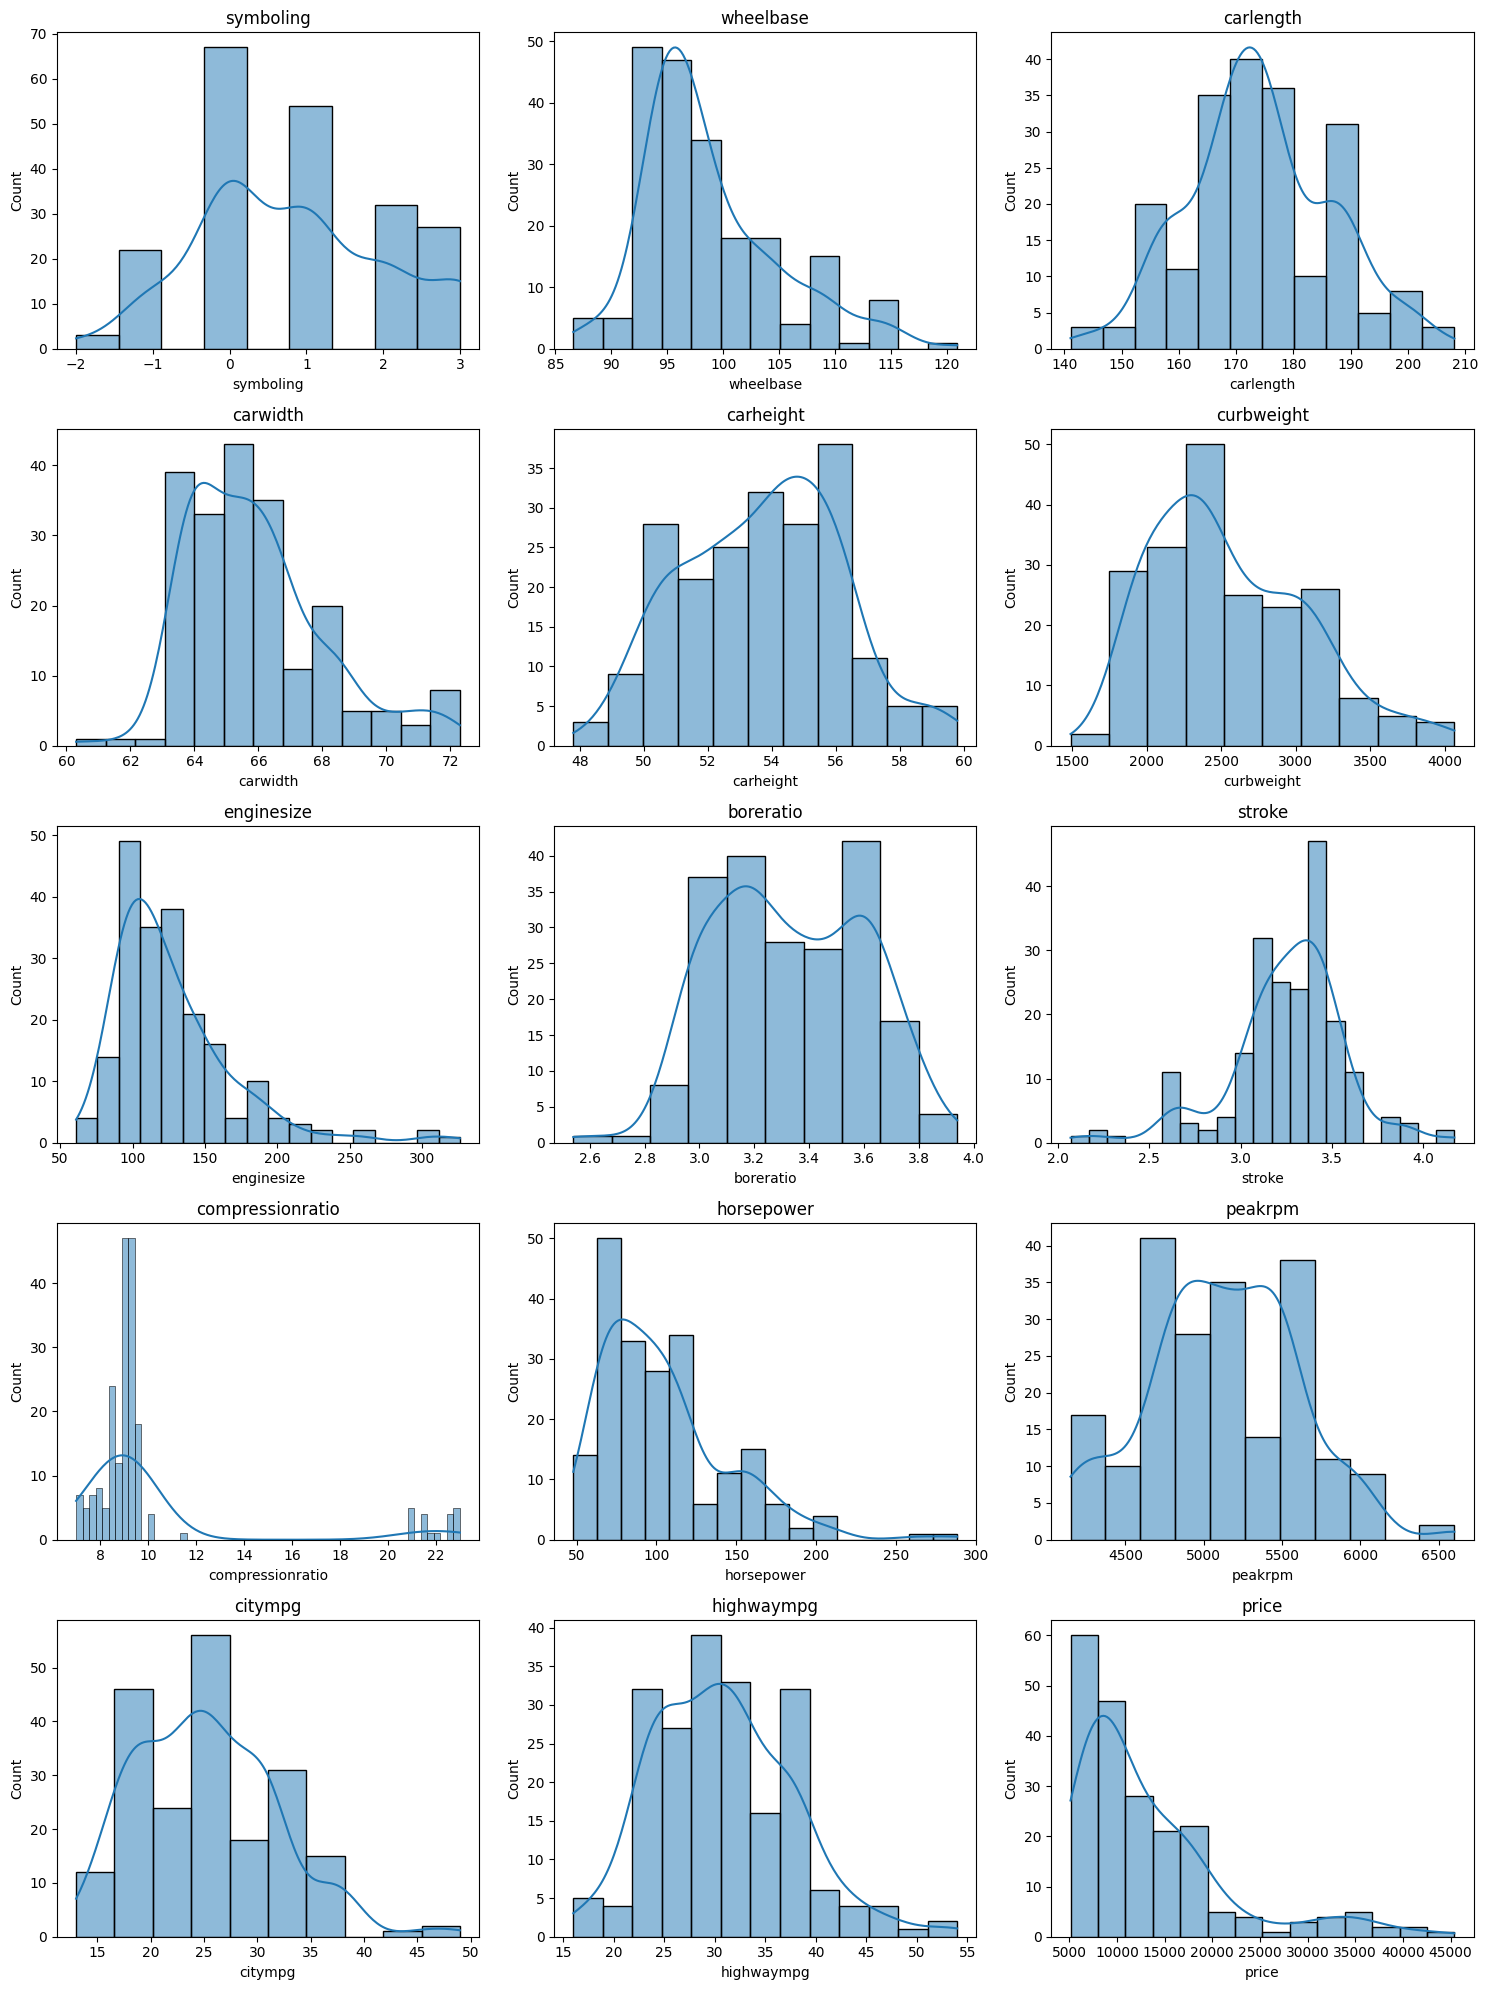

In [ ]:
n = len(numeric_initial)

fig, axes = plt.subplots(nrows=(n + 2) // 3, ncols=3,
                         figsize=(15, 4 * ((n + 2) // 3)))
axes = np.array(axes).reshape(-1)
for ax, col in zip(axes, numeric_initial):
  sns.histplot(df_model[col], kde=True, ax=ax)
  ax.set_title(col)
for ax in axes[len(numeric_initial):]:
  ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [ ]:
X = df_model.drop(columns=["price"])
y = df_model["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

id_train = car_id.loc[X_train.index]
id_test = car_id.loc[X_test.index]

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (164, 24) Test: (41, 24)


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [23]:
cols = [
    c for c in X_train.select_dtypes(include=np.number).columns
    if c != "symboling"
]

q1=X_train[cols]. quantile(0.25)

q3=X_train[cols].quantile(0.75)

iqr = q3 - q1

lower_bounds = q1 - 1.5 * iqr

upper_bounds = q3 + 1.5 * iqr

ouliner_counts = (
(X_train[cols].lt(lower_bounds)) |
(X_train[cols].gt(upper_bounds))
).sum().sort_values(ascending=False)

display(ouliner_counts.to_frame("potential_outliers_train"))

X_train = X_train.copy()
X_test = X_test.copy()

X_train[cols] = X_train[cols].clip(
    lower = lower_bounds,
    upper = upper_bounds,
    axis = 1
)

X_test[cols] = X_test[cols].clip(
    lower = lower_bounds,
    upper = upper_bounds,
    axis = 1
)


,potential_outliers_train
compressionratio,20
stroke,16
carwidth,10
horsepower,7
enginesize,7
wheelbase,6
peakrpm,2
highwaympg,1
boreratio,1
curbweight,0


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


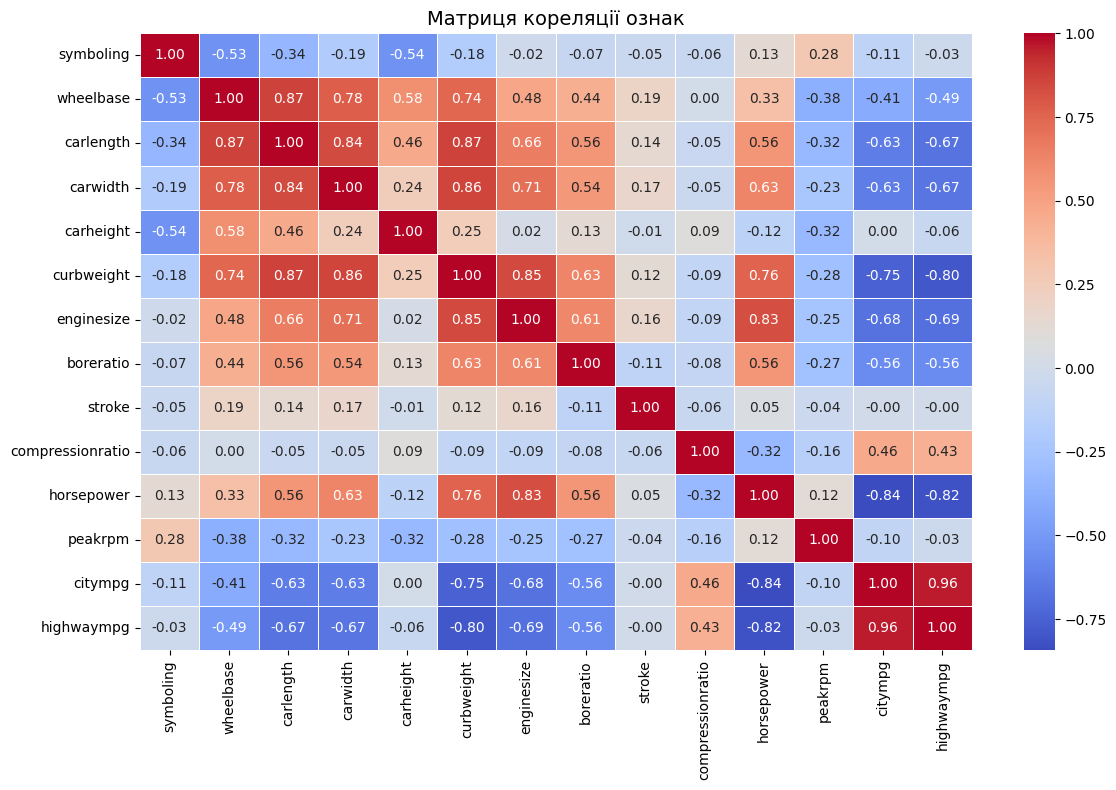

Сильно корельовані пари (|r| > 0.85):
wheelbase — carlength: r = 0.867
carlength — curbweight: r = 0.866
carwidth — curbweight: r = 0.858
citympg — highwaympg: r = 0.964

Ознаки для видалення:
['carlength', 'carwidth', 'citympg', 'wheelbase']

Розміри вибірок після відбору ознак:
X_train: (164, 20)
X_test: (41, 20)


In [24]:
num_train = X_train.select_dtypes(include=np.number).columns

corr = X_train[num_train].corr()

fig, ax = plt.subplots(figsize=(12, 8))

sns.heatmap(
    corr,
    cmap="coolwarm",
    annot=True,
    fmt=".2f",
    square=False,
    cbar=True,
    linewidths=0.5,
    ax=ax
)

plt.title("Матриця кореляції ознак", fontsize=14)
plt.tight_layout()
plt.show()

target_corr = X_train[num_train].corrwith(y_train).abs()

upper = corr.abs().where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

pairs = []

for col in upper.columns:
    for row in upper.index[upper[col] > 0.85]:
        pairs.append(
            (row, col, corr.loc[row, col])
        )

features_to_drop = set()
features_to_keep = set()

for a, b, r in pairs:

    if a in features_to_drop or b in features_to_drop:
        continue

    if target_corr[a] < target_corr[b]:
        features_to_drop.add(a)
        features_to_keep.add(b)
    else:
        features_to_drop.add(b)
        features_to_keep.add(a)

print("Сильно корельовані пари (|r| > 0.85):")

for a, b, r in pairs:
    print(f"{a} — {b}: r = {r:.3f}")

print("\nОзнаки для видалення:")
print(sorted(features_to_drop))

X_train = X_train.drop(
    columns=list(features_to_drop)
)

X_test = X_test.drop(
    columns=list(features_to_drop)
)

print("\nРозміри вибірок після відбору ознак:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [30]:
discrete_features = ["symboling"]

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

continuous_features = [
    col
    for col in X_train.select_dtypes(include=np.number).columns
    if col != "symboling"
]

print("Неперервні числові ознаки:", continuous_features)
print("Дискретні числові ознаки:", discrete_features)
print("Категоріальні ознаки:", categorical_features)

continuous_pipeline = Pipeline([
    ("yeo_johnson", PowerTransformer(method="yeo-johnson")),
    ("scaler", StandardScaler())
])

discrete_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ("continuous", continuous_pipeline, continuous_features),
        ("discrete", discrete_pipeline, discrete_features),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="drop"
)

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)


print("\nРозмір навчальної вибірки до передобробки:", X_train.shape)
print("Розмір тестової вибірки до передобробки:", X_test.shape)

print("\nРозмір навчальної вибірки після передобробки:",
      X_train_processed.shape)
print("Розмір тестової вибірки після передобробки:",
      X_test_processed.shape)

print("\nПередобробку успішно виконано!")


Неперервні числові ознаки: ['carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'highwaympg']
Дискретні числові ознаки: ['symboling']
Категоріальні ознаки: ['fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem', 'brand']

Розмір навчальної вибірки до передобробки: (164, 20)
Розмір тестової вибірки до передобробки: (41, 20)

Розмір навчальної вибірки після передобробки: (164, 73)
Розмір тестової вибірки після передобробки: (41, 73)

Передобробку успішно виконано!


## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [36]:
continuous_cols = [
    col
    for col in X_train.select_dtypes(include=np.number).columns
    if col != "symboling"
]

skewness_before = X_train[continuous_cols].skew()

display(continuous_cols)

['carheight',
 'curbweight',
 'enginesize',
 'boreratio',
 'stroke',
 'compressionratio',
 'horsepower',
 'peakrpm',
 'highwaympg']

## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [37]:
models = {
    "Linear Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]),

    "Ridge Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", Ridge(alpha=1.0))
    ]),

    "Lasso Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", Lasso(alpha=0.1, max_iter=10000))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(random_state=42))
    ]),

    "Gradient Boosting": Pipeline([
        ("preprocessor", preprocessor),
        ("model", GradientBoostingRegressor(random_state=42))
    ]),

    "SVR": Pipeline([
        ("preprocessor", preprocessor),
        ("model", SVR())
    ])
}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results[name] = {
        "R²": r2_score(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred)
    }

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Linear Regression,Ridge Regression,Lasso Regression,Random Forest,Gradient Boosting,SVR
R²,8.759000e-01,8.519000e-01,8.792000e-01,9.532000e-01,9.340000e-01,-9.970000e-02
MAE,2.225258e+03,2.408984e+03,2.143378e+03,1.370500e+03,1.685737e+03,5.696737e+03
MSE,9.798850e+06,1.169038e+07,9.535818e+06,3.692541e+06,5.209854e+06,8.681707e+07


## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [38]:
results = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)


    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100


    results[name] = {
        "R²": r2,
        "MAE": mae,
        "MSE": mse,
        "MAPE (%)": mape
    }

results_df = pd.DataFrame(results).T

results_df = results_df.sort_values(by="R²", ascending=False)

display(results_df.round(4))

,R²,MAE,MSE,MAPE (%)
Random Forest,0.9532,1370.5003,3.692541e+06,9.9046
Gradient Boosting,0.9340,1685.7373,5.209854e+06,11.8412
Lasso Regression,0.8792,2143.3778,9.535818e+06,15.8803
Linear Regression,0.8759,2225.2579,9.798850e+06,17.2248
Ridge Regression,0.8519,2408.9844,1.169038e+07,18.7560
SVR,-0.0997,5696.7373,8.681707e+07,36.0271


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


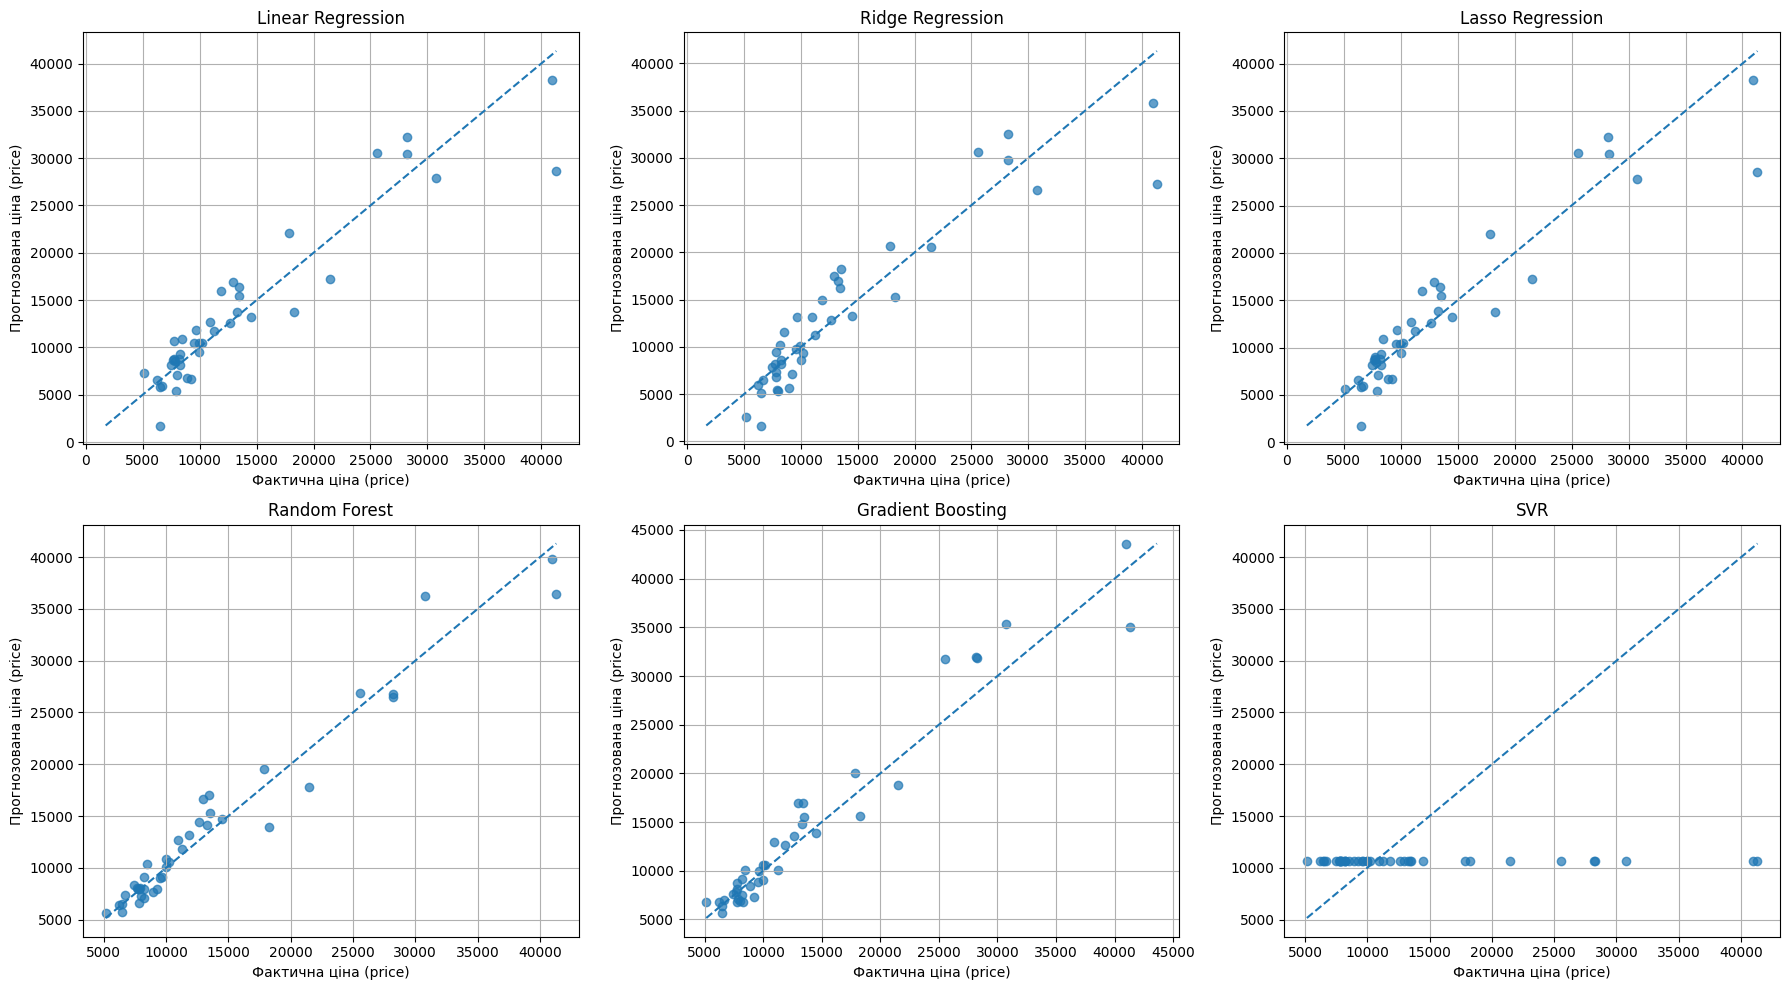

In [46]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):

    y_pred = model.predict(X_test)

    axes[i].scatter(y_test, y_pred, alpha=0.7)

    min_price = min(y_test.min(), y_pred.min())
    max_price = max(y_test.max(), y_pred.max())

    axes[i].plot(
        [min_price, max_price],
        [min_price, max_price],
        linestyle="--"
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Фактична ціна (price)")
    axes[i].set_ylabel("Прогнозована ціна (price)")
    axes[i].grid(True)

plt.tight_layout()
plt.show()

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [45]:
sample_X = X_test.sample(n=10, random_state=42)

sample_y = y_test.loc[sample_X.index]

sample_ids = car_id.loc[sample_X.index]

rf_model = models["Random Forest"]

y_pred = rf_model.predict(sample_X)

comparison = pd.DataFrame({
    "car_ID": sample_ids.to_numpy(),
    "Фактична ціна": sample_y.to_numpy(),
    "Прогнозована ціна": y_pred,
})

comparison["Абсолютна помилка"] = abs(
    comparison["Фактична ціна"] - comparison["Прогнозована ціна"]
)

comparison["Абсолютна відсоткова помилка (%)"] = (
    comparison["Абсолютна помилка"]
    / comparison["Фактична ціна"].abs()
    * 100
)

display(comparison.round(2))

,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна помилка,Абсолютна відсоткова помилка (%)
0,26,6692.0,7372.16,680.16,10.16
1,176,9988.0,10864.19,876.19,8.77
2,148,10198.0,10600.32,402.32,3.95
3,17,41315.0,36414.22,4900.78,11.86
4,69,28248.0,26525.60,1722.40,6.10
5,147,7463.0,8299.67,836.67,11.21
6,144,9960.0,10089.45,129.45,1.30
7,85,14489.0,14686.03,197.03,1.36
8,195,12940.0,16680.93,3740.93,28.91
9,160,7788.0,7965.85,177.85,2.28


## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
